# Global Sensitivity Analysis of Plasma Instabilities via Active Subspaces

__Soraya Terrab__, Department of Applied Mathematics and Statistics, Colorado School of Mines, Golden, CO 80401, USA

__Stephen Pankavich__, Department of Applied Mathematics and Statistics, Colorado School of Mines, Golden, CO 80401, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes about 10 s.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import plasma_dispersion_model as pm
import generate_data as gd

SEED = 2024                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
labels = [r'$k$', r'$\mu_1$', r'$\mu_2$', r'$\sigma_1^2$', r'$\sigma_2^2$', r'$\beta$']

### Summary

Terrab and Pankavich [[1]](https://doi.org/10.1016/j.cnsns.2024.107994) measure how the growth rate $\gamma$ of electrostatic instabilities in a collisionless plasma (the linearized 1-D Vlasov–Poisson system) depends on the parameters of the equilibrium, using active subspaces with $\gamma$ computed from the kinetic dispersion relation. We reimplement the dispersion relation in Python with a certified search for the most unstable root and exact implicit-function gradients, and reproduce the paper's global six-input Bi-Maxwellian study ($\eta_1 = 0.746$, $\eta_2 = 0.928$ against the paper's 0.751 and 0.936; the two-dimensional subspaces differ by 3.3°) and its Two-Stream and Double Beam percentage studies. The paper's Bump-on-Tail numbers are reproduced only with $\sigma_1^2 = \sigma_2^2 = 0.25$ and $\mu_1$ held fixed instead of Table II's values, and from 10 % on the fitted curves disagree (at 25 % the weights too): a fifth to a third of those samples are stable, and the paper's values there are not the least-damped root.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

Terrab and Pankavich [[1]](https://doi.org/10.1016/j.cnsns.2024.107994) study the dimensionless 1-D Vlasov–Poisson system for electrons on a fixed ion background, linearized about a spatially homogeneous equilibrium $f_{eq}(v)$. A perturbation $\propto e^{i(kx-\omega t)}$ grows at the rate $\gamma = \mathrm{Im}\,\omega$, where $\omega$ is a root of the kinetic dispersion function (paper Eq. (2))

$$
\varepsilon(k,\omega) = 1 - \frac{1}{k^2}\int \frac{f_{eq}'(v)}{v - \omega/k}\,dv = 0 .
$$

For the **Bi-Maxwellian** equilibrium, a convex combination of two Maxwellians with means $\mu_1,\mu_2$, variances ("thermal velocities") $\sigma_1^2,\sigma_2^2$ and weight $\beta$, it becomes (paper Eq. (5))

$$
k^2\varepsilon = k^2 + \frac{\beta}{\sigma_1^2}\big[1 + A_1 Z(A_1)\big] + \frac{1-\beta}{\sigma_2^2}\big[1 + A_2 Z(A_2)\big],\qquad A_i = \frac{u-\mu_i}{\sqrt{2\sigma_i^2}},\quad u = \frac{\omega}{k},
$$

and for the **Two-Stream** equilibrium $f_{TS} \propto |v-\mu|^2 e^{-|v-\mu|^2/2\sigma^2}$ (paper Eq. (3)) $k^2\varepsilon = k^2 - [1 - 2A^2 + 2(A - A^3)Z(A)]$. $Z(z) = i\sqrt\pi\,w(z)$ is the plasma dispersion function, with $w$ the Faddeeva function (`scipy.special.wofz`); this is the Landau-continued $Z$, so $k^2\varepsilon$ is an entire function of $u$.

**Quantity of interest.** $\gamma = k\,\mathrm{Im}\,u^\ast$, where $u^\ast$ is the root with the largest imaginary part: the most unstable mode, or the least-damped one when the equilibrium is stable. The paper (Sec. IV) solves the dispersion relation in MATLAB with a numerical $Z$ function and does not say which root its solver returns; the comparison below shows where the choice matters.

**Solver** (`plasma_dispersion_model.py`, a reimplementation from the paper's equations). $|k^2\varepsilon|$ is scanned on a grid in the complex $u$-plane (spacing 0.05, $\mathrm{Im}\,u \in [-2.5, 3]$, both beams covered); every local minimum starts a Newton iteration with the analytic $\partial_u(k^2\varepsilon)$. The root with the largest imaginary part is then *certified*: the argument principle counts the zeros in a rectangle from $\mathrm{Im}\,u^\ast - 0.05$ up to a top edge where $|k^2\varepsilon - k^2| < k^2/2$, and the count must equal the number of roots found there. On a mismatch the scan is repeated on a 3× finer grid; a second mismatch, or any Newton failure, raises `RootError`, so the model never returns an uncertified number.

**Gradients** by the implicit function theorem: $\partial u^\ast/\partial x_j = -\partial_{x_j}(k^2\varepsilon)/\partial_u(k^2\varepsilon)$ at the root, and $\partial\gamma/\partial x_j = k\,\mathrm{Im}(\partial u^\ast/\partial x_j)$ plus $\mathrm{Im}\,u^\ast$ for $x_j = k$. They are exact where the most unstable root is simple and isolated; where two roots exchange the lead, $\gamma$ has a kink.

**Inputs.** The main study is the paper's **global Bi-Maxwellian** box (p. 29), $m = 6$, inputs independent and uniform. The **percentage studies** take the baselines of Tables I and II and vary each input by ± a percentage (for a zero baseline, ± the percentage as an absolute value; paper p. 11). All inputs are dimensionless.

In [2]:
print(f"{'input':6s} {'symbol':10s} {'global lower':>12s} {'global upper':>12s} {'Double Beam':>11s} {'Bump-on-Tail':>12s}  description")
for j, n in enumerate(pm.NAMES['bm']):
    print(f"{n:6s} {pm.SYMBOLS['bm'][j]:10s} {pm.GLOBAL_LOWER[j]:12g} {pm.GLOBAL_UPPER[j]:12g} "
          f"{pm.NOMINAL_DB[j]:11g} {pm.NOMINAL_BOT[j]:12g}  {pm.DESCRIPTIONS['bm'][j]}")
print('\nTwo-Stream baseline (Table I):', dict(zip(pm.NAMES['ts'], pm.NOMINAL_TS)))

input  symbol     global lower global upper Double Beam Bump-on-Tail  description
k      k                   0.4          0.6         0.5          0.5  perturbation wavenumber
mu1    mu_1               -0.1          0.1           0            0  mean velocity of beam 1
mu2    mu_2                3.5          4.5           4            4  mean velocity of beam 2
s1     sigma_1^2          0.25         0.75         0.5          0.5  thermal velocity (variance) of beam 1
s2     sigma_2^2          0.25         0.75         0.5          0.5  thermal velocity (variance) of beam 2
beta   beta                0.5         0.99         0.5          0.8  density fraction of beam 1 (scaling parameter)

Two-Stream baseline (Table I): {'k': np.float64(0.5), 'mu': np.float64(0.0), 's': np.float64(1.0)}


The cell below checks the solver against the paper: the Two-Stream growth rate as a function of $k$ (paper Fig. 1) and the baseline growth rates, which are the intercepts $a_0$ of the paper's 1 % quadratic fits (Tables IV, VI, VIII).

In [3]:
from scipy.optimize import minimize_scalar
pk = minimize_scalar(lambda k: -pm.growth_rate([k, 0.0, 1.0], 'ts'), bounds=(0.3, 0.6),
                     method='bounded', options={'xatol': 1e-8})
print(f'Two-Stream, mu = 0, sigma^2 = 1: max over k of gamma = {-pk.fun:.4f} at k = {pk.x:.4f} '
      f'(paper Fig. 1: 0.2649 at k = 0.4241)')
for name, kind, x in [('Two-Stream baseline', 'ts', pm.NOMINAL_TS), ('Double Beam baseline', 'bm', pm.NOMINAL_DB),
                      ('Bump-on-Tail baseline (Table II, sigma^2 = 0.5)', 'bm', pm.NOMINAL_BOT),
                      ('Bump-on-Tail with sigma^2 = 0.25', 'bm', gd.NOMINAL_BOT_S025)]:
    u, info = pm.most_unstable_root(x, kind, return_info=True)
    print(f'{name:48s} omega = {x[0] * u.real:+.4f} {x[0] * u.imag:+.5f}i; next root '
          f'{info["gap"] * x[0]:.3f} lower in gamma')

Two-Stream, mu = 0, sigma^2 = 1: max over k of gamma = 0.2649 at k = 0.4280 (paper Fig. 1: 0.2649 at k = 0.4241)
Two-Stream baseline                              omega = +0.0000 +0.25925i; next root 0.410 lower in gamma
Double Beam baseline                             omega = +1.0000 +0.18486i; next root 0.285 lower in gamma
Bump-on-Tail baseline (Table II, sigma^2 = 0.5)  omega = +1.1712 +0.12660i; next root 0.180 lower in gamma
Bump-on-Tail with sigma^2 = 0.25                 omega = +1.1605 +0.12101i; next root 0.127 lower in gamma


### Load data

`generate_data.py` drew the samples (seed 2024) and wrote, for each, the physical inputs, $\gamma$, $\omega_r$, the exact gradient of $\gamma$ with respect to the physical inputs, and the gap to the next root (see `DATA.md`). The main study is `global_bimaxwellian.csv` ($M = 1000$); the percentage studies have 512 samples per percentage, the paper's $N$.

In [4]:
def split(A, kind, has_pct=True):
    """Columns: [pct,] inputs (m), gamma, omega_r, dgamma/dinputs (m), gap."""
    m, o = len(pm.NAMES[kind]), int(has_pct)
    return dict(pct=A[:, 0] if has_pct else None, X=A[:, o:o + m], f=A[:, o + m], wr=A[:, o + m + 1],
                G=A[:, o + m + 2:o + 2 * m + 2], gap=A[:, -1])

D = {s: split(np.loadtxt(fn, delimiter=','), kind, s != 'global') for s, (fn, kind, _) in gd.STUDIES.items()}
X, f, G = D['global']['X'], D['global']['f'], D['global']['G']
for s, d in D.items():
    print(f'{s:18s} X {d["X"].shape}, gamma {d["f"].shape}, gradients {d["G"].shape}'
          + ('' if d['pct'] is None else f', pct in {sorted(set(d["pct"].astype(int)))}'))

global             X (1000, 6), gamma (1000,), gradients (1000, 6)
double_beam        X (3072, 6), gamma (3072,), gradients (3072, 6), pct in [np.int64(1), np.int64(5), np.int64(10), np.int64(15), np.int64(20), np.int64(25)]
bump_on_tail       X (2560, 6), gamma (2560,), gradients (2560, 6), pct in [np.int64(1), np.int64(5), np.int64(10), np.int64(15), np.int64(25)]
bump_on_tail_s025  X (2560, 6), gamma (2560,), gradients (2560, 6), pct in [np.int64(1), np.int64(5), np.int64(10), np.int64(15), np.int64(25)]
two_stream         X (3584, 3), gamma (3584,), gradients (3584, 3), pct in [np.int64(1), np.int64(5), np.int64(10), np.int64(15), np.int64(20), np.int64(25), np.int64(50)]


We re-solve five samples and compare the stored gradients with central differences of the model in normalized coordinates.

In [5]:
rows = np.random.default_rng(SEED).choice(len(f), 5, replace=False)
lo, hi = pm.GLOBAL_LOWER, pm.GLOBAL_UPPER
half = (hi - lo) / 2
h = 1e-5
err_f, err_g = [], []
for i in rows:
    err_f.append(abs(pm.growth_rate(X[i]) - f[i]))
    g_fd = np.array([(pm.growth_rate(X[i] + h * half[j] * e) - pm.growth_rate(X[i] - h * half[j] * e)) / (2 * h)
                     for j, e in enumerate(np.eye(6))])
    err_g.append(np.linalg.norm(g_fd - G[i] * half) / np.linalg.norm(G[i] * half))
print(f'5 samples re-solved: max |gamma - file| = {max(err_f):.1e}; normalized gradient vs central '
      f'differences (h = 1e-5): max relative error {max(err_g):.1e}')
print(f'gamma: range [{f.min():.4f}, {f.max():.4f}], mean {f.mean():.4f}; {np.mean(f < 0):.1%} of the samples are '
      f'stable (gamma < 0)')
print(f'samples whose next root is within 1e-3 in gamma (near a branch crossing): '
      f'{np.sum(D["global"]["gap"] < 1e-3)} of {len(f)}')

5 samples re-solved: max |gamma - file| = 0.0e+00; normalized gradient vs central differences (h = 1e-5): max relative error 3.4e-09
gamma: range [-0.1651, 0.2854], mean 0.1072; 14.9% of the samples are stable (gamma < 0)
samples whose next root is within 1e-3 in gamma (near a branch crossing): 2 of 1000


### Estimate the subspace

The model gives exact gradients, so we use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates $\mathbf x\in[-1,1]^6$. We pass the physical inputs and physical gradients with `ac.Uniform(lower, upper)`, and the library maps both to $[-1,1]^6$ once (the paper's Eq. (10)). We use 500 bootstrap replicates. The paper uses a two-dimensional subspace for this box, so we fix $n = 2$ and orient $\mathbf w_1, \mathbf w_2$ to match the signs of the paper's vectors.

In [6]:
space = ac.Uniform(pm.GLOBAL_LOWER, pm.GLOBAL_UPPER, names=list(pm.NAMES['bm']))
sub0 = ac.active_subspace(space=space, X=X, f=f, grads=G, estimator='as', nboot=500, rng=SEED)
ks, crit, k_hat = ac.dimension_criterion(sub0, rule='evg')
W1_PAPER = np.array([0.588, -0.058, 0.29, 0.06, 0.04, 0.75])
W2_PAPER = np.array([-0.567, 0.097, -0.488, 0.143, 0.163, 0.619])
sub = ac.orient(ac.with_dimension(sub0, 2), by='reference', reference=np.column_stack([W1_PAPER, W2_PAPER]),
                columns=2)
lam = sub.eigenvalues
eta = np.cumsum(lam) / lam.sum()
print('eigenvalues:', np.array2string(lam, precision=3))
print(f'library default n = {sub0.n}; eigenvalue-gap rule picks {k_hat}; we use n = 2 (as the paper)')
print('lambda_k/lambda_k+1:', np.array2string(lam[:-1] / lam[1:], precision=2))
print(f'eta_1 = {eta[0]:.4f}, eta_2 = {eta[1]:.4f}, eta_3 = {eta[2]:.4f} (paper: 0.7509, 0.9358)')

eigenvalues: [2.679e-02 6.543e-03 1.968e-03 5.401e-04 6.704e-05 5.206e-31]
library default n = 1; eigenvalue-gap rule picks 1; we use n = 2 (as the paper)
lambda_k/lambda_k+1: [4.09e+00 3.32e+00 3.64e+00 8.06e+00 1.29e+26]
eta_1 = 0.7461, eta_2 = 0.9283, eta_3 = 0.9831 (paper: 0.7509, 0.9358)


### Results

**Eigenvalues.** The figure shows the eigenvalues with a 95 % bootstrap band.

lambda_1 = 2.679e-02  (bootstrap 95 % [2.496e-02, 2.900e-02])
lambda_2 = 6.543e-03  (bootstrap 95 % [5.665e-03, 7.381e-03])
lambda_3 = 1.968e-03  (bootstrap 95 % [1.772e-03, 2.132e-03])
lambda_4 = 5.401e-04  (bootstrap 95 % [4.041e-04, 6.702e-04])
lambda_5 = 6.704e-05  (bootstrap 95 % [5.837e-05, 7.504e-05])
lambda_6 = 5.206e-31  (bootstrap 95 % [2.963e-31, 7.891e-31])


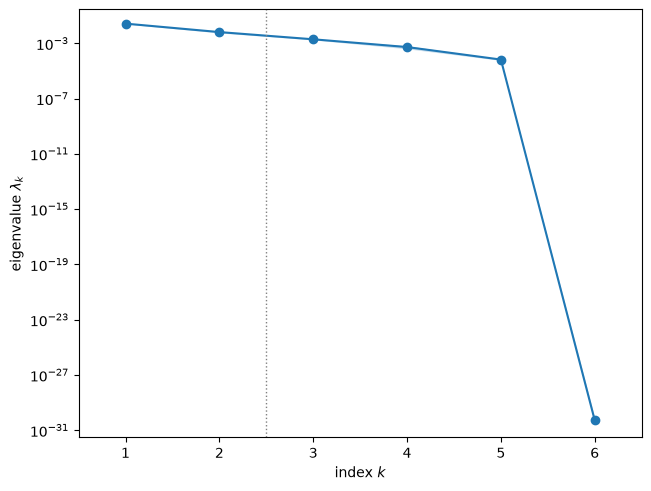

In [7]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
lo95, hi95 = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
for k in range(6):
    print(f'lambda_{k + 1} = {lam[k]:.3e}  (bootstrap 95 % [{lo95[k]:.3e}, {hi95[k]:.3e}])')
fig

The eigenvalues fall off steadily, by factors of 4.09, 3.32, 3.64 and 8.06 from $\lambda_1 = 2.68\times10^{-2}$ to $\lambda_5 = 6.70\times10^{-5}$, so there is no large gap and the eigenvalue-gap rule picks $n = 1$. The first eigenvalue carries $\eta_1 = 74.6$ % of the sum and the first two $\eta_2 = 92.8$ % (paper: 75.09 % and 93.58 %). $\lambda_6 = 5.2\times10^{-31}$ is exactly zero up to rounding: $\gamma$ depends on $\mu_1$ and $\mu_2$ only through $\mu_2-\mu_1$ (shifting both beams shifts only $\omega_r$, paper p. 15), so the gradient is always orthogonal to the direction that moves both means together.

bootstrap mean subspace distance, k = 1..5: [3.163e-02 3.811e-02 3.196e-02 2.100e-02 6.248e-15]


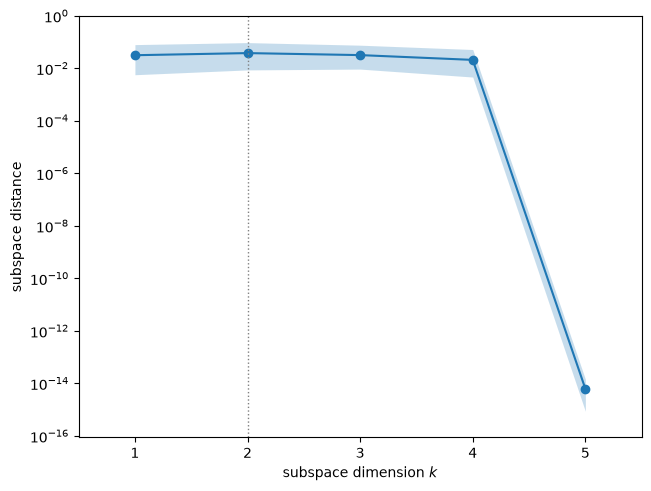

In [8]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..5:', np.array2string(ac.mean_distance(sub), precision=3))
fig

The bootstrap mean subspace distances are 0.032, 0.038, 0.032 and 0.021 for $k = 1,\dots,4$, so the first and the first two eigenvectors are well determined by the 1000 samples even without a large gap; the distance for $k = 5$ is $7.6\times10^{-15}$ because the sixth direction is the exactly null one.

w1        : [ 0.582 -0.059  0.297  0.072  0.027  0.751]
w1 (paper): [ 0.588 -0.058  0.29   0.06   0.04   0.75 ]
w2        : [-0.58   0.095 -0.476  0.096  0.14   0.632]
w2 (paper): [-0.567  0.097 -0.488  0.143  0.163  0.619]
angle between span(w1, w2) here and in the paper: 3.3 degrees
w1[mu1]/w1[mu2] = -0.2000, w2[mu1]/w2[mu2] = -0.2000 (Galilean invariance: -(0.1)/(0.5) = -0.2)


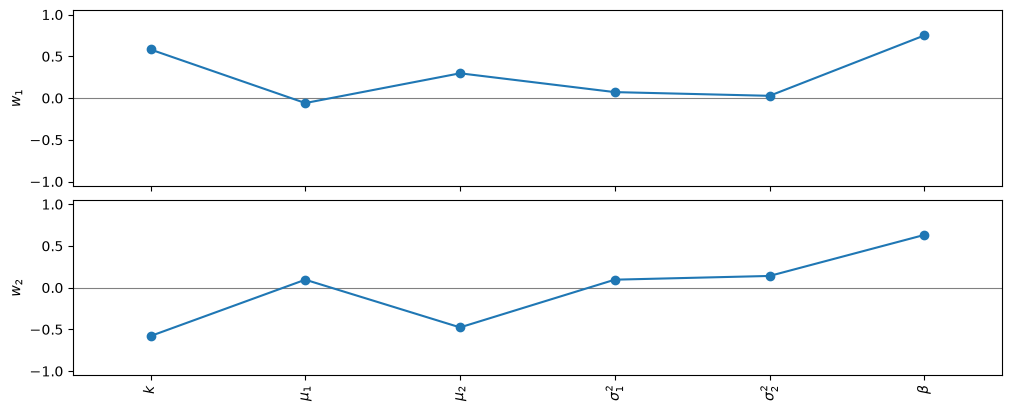

In [9]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(10, 4))
plt.close(fig)
w1, w2 = sub.W[:, 0], sub.W[:, 1]
print('w1        :', np.array2string(w1, precision=3))
print('w1 (paper):', W1_PAPER)
print('w2        :', np.array2string(w2, precision=3))
print('w2 (paper):', W2_PAPER)
print(f'angle between span(w1, w2) here and in the paper: '
      f'{np.degrees(np.arccos(np.clip(np.linalg.svd(np.linalg.qr(sub.W[:, :2])[0].T @ np.linalg.qr(np.column_stack([W1_PAPER, W2_PAPER]))[0], compute_uv=False).min(), -1, 1))):.1f} degrees')
print(f'w1[mu1]/w1[mu2] = {w1[1] / w1[2]:.4f}, w2[mu1]/w2[mu2] = {w2[1] / w2[2]:.4f} '
      f'(Galilean invariance: -(0.1)/(0.5) = -0.2)')
fig

$\mathbf w_1$ weights $\beta$ (0.751) and $k$ (0.582) most, then $\mu_2$ (0.297), and agrees with the paper's vector to 0.013 in every entry; $\mathbf w_2$ contrasts $k$ and $\mu_2$ (−0.58, −0.476) with $\beta$ (0.632), as in the paper, with entries within 0.047. The angle between the two-dimensional subspaces here and in the paper is 3.3°. In both vectors the $\mu_1$ and $\mu_2$ weights stand in the ratio −0.2000, which is −(range of $\mu_1$)/(range of $\mu_2$) = −0.1/0.5: the Galilean invariance above.

y1 in [-1.38, 1.49], y2 in [-1.63, 1.51]
correlation of gamma with y1: -0.910


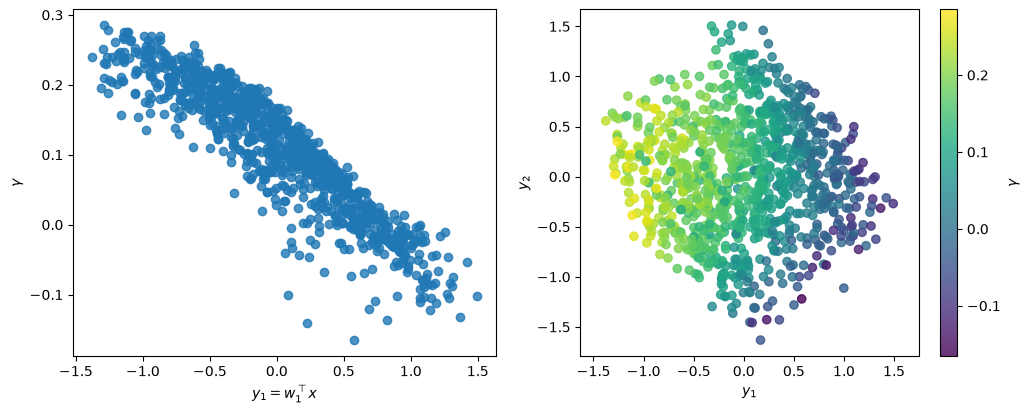

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label=r'$\gamma$', ax=axes[0])
ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=2, qoi_label=r'$\gamma$', ax=axes[1])
plt.close(fig)
Y = space.to_normalized(X) @ sub.W[:, :2]
print(f'y1 in [{Y[:, 0].min():.2f}, {Y[:, 0].max():.2f}], y2 in [{Y[:, 1].min():.2f}, {Y[:, 1].max():.2f}]')
r = np.corrcoef(Y[:, 0], f)[0, 1]
print(f'correlation of gamma with y1: {r:.3f}')
fig

$\gamma$ decreases along $y_1$ (correlation −0.910), from about 0.28 at $y_1 \approx -1.4$ to about −0.1 at $y_1 \approx 1.5$, and the spread around the trend is the dependence on $y_2$: in the two-dimensional plot $\gamma$ is largest at negative $y_1$ and $y_2$ near 0. Of the 1000 samples, 14.9 % are stable ($\gamma < 0$), and they include the scattered points below the trend at $0 < y_1 < 0.6$. Two samples have a second root within $10^{-3}$ of the most unstable one in $\gamma$, where $\gamma$ has a kink.

#### Surrogates on the active variables

Polynomial surrogates in the active variables, with leave-one-out $R^2$, and the paper's own quadratic $h(y_1,y_2)$ (p. 30) evaluated on our samples with the paper's $\mathbf w_1, \mathbf w_2$.

LOO R^2: quadratic in y1 0.8382; quadratic in (y1, y2) 0.9136; cubic in (y1, y2) 0.9301
quadratic in y1 (least squares): -0.0233 y^2 -0.1389 y +0.1151   (paper Table VIII, Global: -0.0263 y^2 - 0.1348 y + 0.1204)
our quadratic in (y1, y2): +0.1394 -0.1385 y1 +0.0174 y2 -0.0038 y1 y2 -0.0392 y1^2 -0.0565 y2^2
R^2 of the paper's h(y1, y2) (p. 30) on these samples: 0.875


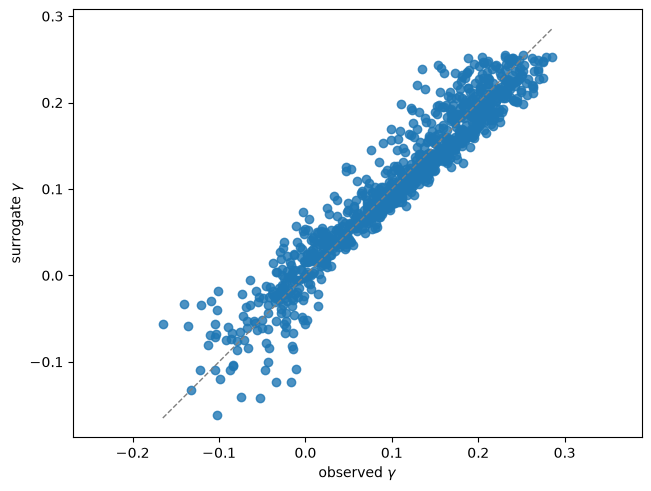

In [11]:
sur1 = ac.fit_surrogate(X=X, f=f, subspace=ac.with_dimension(sub, 1), kind='poly', degree=2)
sur2 = ac.fit_surrogate(X=X, f=f, subspace=sub, kind='poly', degree=2)
sur3 = ac.fit_surrogate(X=X, f=f, subspace=sub, kind='poly', degree=3)
a1d = np.polyfit(Y[:, 0], f, 2)
print(f'LOO R^2: quadratic in y1 {sur1.loo_r_squared:.4f}; quadratic in (y1, y2) {sur2.loo_r_squared:.4f}; '
      f'cubic in (y1, y2) {sur3.loo_r_squared:.4f}')
print(f'quadratic in y1 (least squares): {a1d[0]:.4f} y^2 {a1d[1]:+.4f} y {a1d[2]:+.4f}   '
      f'(paper Table VIII, Global: -0.0263 y^2 - 0.1348 y + 0.1204)')
# the paper's global quadratic h(y1, y2) with its own w1, w2, evaluated on our samples
Yp = space.to_normalized(X) @ np.column_stack([W1_PAPER, W2_PAPER])
h_paper = 0.1278 - 0.125 * Yp[:, 0] + 0.016 * Yp[:, 1] + 0.017 * Yp[:, 0] * Yp[:, 1] - 0.044 * Yp[:, 1] ** 2
r2_paper = 1 - np.sum((f - h_paper) ** 2) / np.sum((f - f.mean()) ** 2)
B = np.column_stack([np.ones(len(f)), Y[:, 0], Y[:, 1], Y[:, 0] * Y[:, 1], Y[:, 0] ** 2, Y[:, 1] ** 2])
c = np.linalg.lstsq(B, f, rcond=None)[0]
print('our quadratic in (y1, y2): ' + ' '.join(f'{v:+.4f}{t}' for v, t in zip(c, ['', ' y1', ' y2', ' y1 y2', ' y1^2', ' y2^2'])))
print(f"R^2 of the paper's h(y1, y2) (p. 30) on these samples: {r2_paper:.3f}")
fig, ax = ac.plotting.plot_surrogate_fit(sur2, X=X, f=f, qoi_label=r'$\gamma$')
plt.close(fig)
fig

A quadratic in $y_1$ alone has leave-one-out $R^2 = 0.838$, a quadratic in $(y_1, y_2)$ 0.914 and a cubic 0.930. Our one-dimensional quadratic, $-0.0233\,y^2 - 0.1389\,y + 0.1151$, is close to the paper's Global row of Table VIII ($-0.0263$, $-0.1348$, 0.1204). The paper's two-dimensional quadratic (p. 30), evaluated with its own $\mathbf w_1, \mathbf w_2$ on our samples, has $R^2 = 0.875$; it has no $y_1^2$ term, while our least-squares fit has $-0.0392\,y_1^2$, and the other coefficients agree in sign and roughly in size.

#### The percentage studies (Tables III–VIII)

For each percentage study we estimate the subspace from the 512 exact gradients (`ac.active_subspace`, 200 bootstrap replicates), orient $\mathbf w_1$ so that its weight on $k$ is positive (the paper's sign), and fit a quadratic in $y = \mathbf w_1^T\mathbf x$ by least squares, as the paper does. Two Bump-on-Tail data sets are included: `bump_on_tail` uses the baseline of Table II ($\sigma_1^2 = \sigma_2^2 = 0.5$, $\mu_1$ varied by ± the percentage in absolute value), and `bump_on_tail_s025` uses $\sigma_1^2 = \sigma_2^2 = 0.25$ with $\mu_1$ held at 0, the setup that the paper's Bump-on-Tail numbers imply (see below).

In [12]:
PAPER = {  # (pct): (eta1 in % or None, w1, (a2, a1, a0)); Tables III-VIII, figure captions
    'two_stream': {1: (99.97, [0.5068, 1.2054e-4, -0.8620], (-3.2966e-6, -0.0015, 0.2592)),
                   5: (None, [0.5106, 1.1535e-5, -0.8598], (-0.0001, -0.0075, 0.2591)),
                   10: (None, [0.5225, -2.1606e-6, -0.8527], (-0.0003, -0.0150, 0.2584)),
                   15: (94.00, [0.5385, 2.7751e-6, -0.8426], (-0.0008, -0.0223, 0.2575)),
                   20: (None, [0.5605, -3.9831e-6, -0.8281], (-0.0014, -0.0297, 0.2561)),
                   25: (85.38, [0.5903, 4.5345e-7, -0.8072], (-0.0024, -0.0366, 0.2544)),
                   50: (60, [0.8974, -1.9074e-6, -0.4412], (-0.0313, -0.0556, 0.2473))},
    'double_beam': {1: (99.92, [0.8666, -0.1159, 0.4640, 0.1006, 0.1009, -4.6515e-5], (-0.0002, -0.0053, 0.1848)),
                    5: (98.42, [0.8513, -0.1235, 0.4943, 0.0887, 0.0888, -0.0002], (-0.0046, -0.0267, 0.1845)),
                    10: (None, [0.8017, -0.1438, 0.5752, 0.0539, 0.0542, -0.0002], (-0.0213, -0.0550, 0.1838)),
                    15: (94.61, [0.6970, -0.1739, 0.6956, -0.0077, -0.0063, 0.0031], (-0.0612, -0.0886, 0.1850)),
                    20: (None, [0.6423, -0.1843, 0.7421, -0.0333, -0.0395, -0.0065], (-0.1179, -0.1321, 0.1842)),
                    25: (91.55, [0.6206, -0.1898, 0.7589, -0.0393, -0.0354, 0.0061], (-0.1492, -0.1632, 0.1772))},
    'bump_on_tail': {1: (99.97, [0.6081, 0, 0.7168, -0.0271, -0.0276, 0.3390], (-0.0012, -0.0172, 0.1210)),
                     5: (None, [0.6019, 0, 0.7339, -0.0295, -0.0398, 0.3109], (-0.0226, -0.0902, 0.1185)),
                     10: (98.34, [0.6071, 0, 0.7307, -0.0286, -0.0397, 0.3085], (-0.0489, -0.1610, 0.1136)),
                     15: (None, [0.6230, 0, 0.7077, -0.0258, -0.0351, 0.3303], (-0.0825, -0.2200, 0.1109)),
                     25: (89.38, [0.6675, 0, 0.6891, -0.0266, -0.0377, 0.2783], (-0.1308, -0.2888, 0.1061))},
}
PAPER['bump_on_tail_s025'] = PAPER['bump_on_tail']

def pct_study(study):
    fn, kind, boxes = gd.STUDIES[study]
    d, out = D[study], {}
    for pct, lo_, hi_ in boxes:
        sel = d['pct'] == pct
        Xs, fs, Gs = d['X'][sel], d['f'][sel], d['G'][sel]
        keep = hi_ > lo_                       # mu1 is held (zero range) in bump_on_tail_s025
        s = ac.active_subspace(space=ac.Uniform(lo_[keep], hi_[keep]), X=Xs[:, keep], f=fs, grads=Gs[:, keep],
                               estimator='as', nboot=200, rng=SEED)
        w = np.zeros(len(keep))
        w[keep] = s.W[:, 0] * np.sign(s.W[0, 0])            # paper's sign: weight on k > 0
        y = s.space.to_normalized(Xs[:, keep]) @ w[keep]
        e = np.cumsum(s.eigenvalues) / s.eigenvalues.sum()
        out[pct] = dict(eta1=100 * e[0], eta2=100 * e[1], w=w, a=np.polyfit(y, fs, 2), y=y, f=fs,
                        neg=np.mean(fs < 0), near=np.sum(d['gap'][sel] < 1e-3))
    return out

R = {s: pct_study(s) for s in ['two_stream', 'double_beam', 'bump_on_tail', 'bump_on_tail_s025']}
for s, res in R.items():
    print(f'--- {s}   (each line: here / paper)')
    for pct, r in res.items():
        pe, pw, pa = PAPER[s][pct]
        print(f'{pct:3d} %  eta1 {r["eta1"]:6.2f} / {"-" if pe is None else pe}  (eta2 {r["eta2"]:.3f})  '
              f'max|w1 - paper| {np.max(np.abs(r["w"] - pw)):.4f}')
        print(f'        w1 {np.array2string(r["w"], precision=4, suppress_small=True)} / {pw}')
        print(f'        fit a2, a1, a0 {np.array2string(r["a"], precision=4)} / {list(pa)};  gamma < 0 in '
              f'{r["neg"]:.1%}, near-crossings {r["near"]}')

--- two_stream   (each line: here / paper)
  1 %  eta1  99.97 / 99.97  (eta2 100.000)  max|w1 - paper| 0.0006
        w1 [ 0.5062  0.     -0.8624] / [0.5068, 0.00012054, -0.862]
        fit a2, a1, a0 [-3.0449e-06 -1.5037e-03  2.5924e-01] / [-3.2966e-06, -0.0015, 0.2592];  gamma < 0 in 0.0%, near-crossings 0
  5 %  eta1  99.25 / -  (eta2 100.000)  max|w1 - paper| 0.0059
        w1 [ 0.5047  0.     -0.8633] / [0.5106, 1.1535e-05, -0.8598]
        fit a2, a1, a0 [-5.3219e-05 -7.4980e-03  2.5903e-01] / [-0.0001, -0.0075, 0.2591];  gamma < 0 in 0.0%, near-crossings 0
 10 %  eta1  97.33 / -  (eta2 100.000)  max|w1 - paper| 0.0059
        w1 [ 0.5166  0.     -0.8562] / [0.5225, -2.1606e-06, -0.8527]
        fit a2, a1, a0 [-0.0003 -0.015   0.2585] / [-0.0003, -0.015, 0.2584];  gamma < 0 in 0.0%, near-crossings 0
 15 %  eta1  93.78 / 94.0  (eta2 100.000)  max|w1 - paper| 0.0185
        w1 [ 0.52    0.     -0.8542] / [0.5385, 2.7751e-06, -0.8426]
        fit a2, a1, a0 [-0.0007 -0.0223  0.2574

**Two-Stream** ($m = 3$, Tables III–IV). $\eta_1$ is 99.97 %, 93.78 % and 84.77 % at 1, 15 and 25 % (paper 99.97, 94.00, 85.38), and 65.22 % at 50 % (paper "≈ 60 %"). $\mathbf w_1$ agrees with Table III to 0.033 or better, the weight on $\mu$ is exactly zero (the paper's are $10^{-4}$–$10^{-7}$, presumably finite-difference noise), and the quadratic coefficients agree to $5\times10^{-4}$ up to 25 % and to 0.005 at 50 %. $\eta_2 = 100$ % because $\gamma$ does not depend on $\mu$.

**Double Beam** (Tables V–VI). $\eta_1$ is 99.93, 98.17, 94.28 and 92.47 % at 1, 5, 15 and 25 % (paper 99.92, 98.42, 94.61, 91.55), $\mathbf w_1$ agrees with Table V to 0.042 or better, and the quadratic coefficients to 0.02 or better (the largest difference is $a_2$ at 20 %: −0.0991 against −0.1179). $\eta_2$ is 99.999 % at 1 % and 98.610 % at 25 % (paper 99.995 % and 98.8 %). Up to 14.6 % of the samples (25 %) are stable here, and the paper's curves follow ours into the stable region.

**Bump-on-Tail with Table II's baseline** ($\sigma_1^2 = \sigma_2^2 = 0.5$) does **not** reproduce Table VII: at 1 %, $\mathbf w_1$ differs by up to 0.245, the baseline growth rate is 0.1265 against the paper's $a_0 = 0.1210$, and $\mu_1$ has weight −0.118 where the paper's is exactly 0 ($1.1\times10^{-16}$). Two changes reproduce it: $\sigma_1^2 = \sigma_2^2 = 0.25$ (as if the 0.5 of Table II were $\sigma$, not $\sigma^2$) and $\mu_1$ held at 0 (as if its range were 1 % of 0 rather than ± 0.01). With them (`bump_on_tail_s025`), the 1 % study matches Tables VII and VIII to about $10^{-3}$ ($\eta_1$ 99.97 % for both; $a_0$ 0.121), and $\mathbf w_1$ matches to 0.0026, 0.0007 and 0.0063 at 5, 10 and 15 %. At 25 % $\mathbf w_1$ differs by 0.154 (the weight on $\beta$ is 0.432 against 0.278) and $\eta_1$ is 82.58 % against 89.38 %. The quadratic fits differ from 10 % on: $a_2 = +0.0038$ against −0.0489 at 10 % and +0.0358 against −0.1308 at 25 %. At these percentages 17.0 %, 27.7 % and 33.2 % of the samples (10, 15, 25 %) are stable.

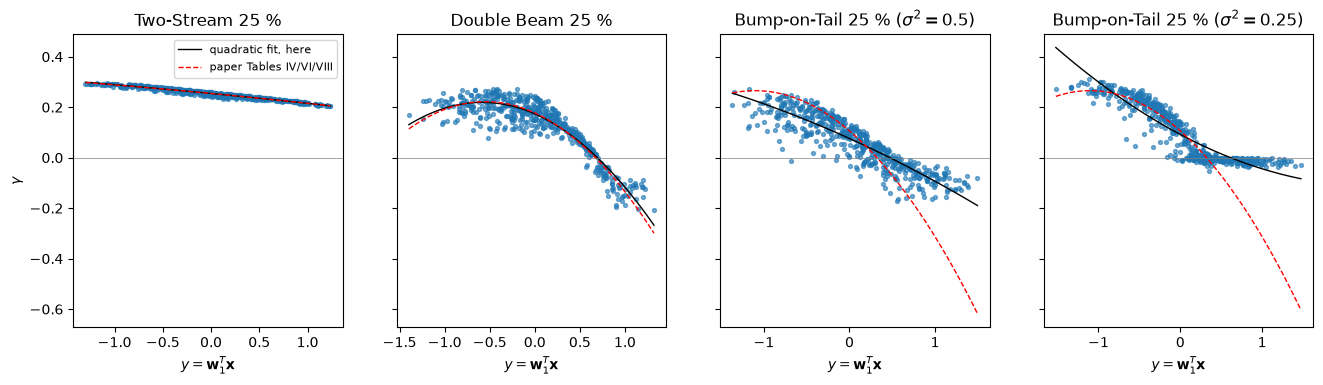

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (s, pct, title) in zip(axes, [('two_stream', 25, 'Two-Stream 25 %'), ('double_beam', 25, 'Double Beam 25 %'),
                                      ('bump_on_tail', 25, r'Bump-on-Tail 25 % ($\sigma^2 = 0.5$)'),
                                      ('bump_on_tail_s025', 25, r'Bump-on-Tail 25 % ($\sigma^2 = 0.25$)')]):
    r = R[s][pct]
    ax.scatter(r['y'], r['f'], s=8, alpha=0.6)
    ys = np.linspace(r['y'].min(), r['y'].max(), 100)
    ax.plot(ys, np.polyval(r['a'], ys), 'k-', lw=1, label='quadratic fit, here')
    ax.plot(ys, np.polyval(PAPER[s][pct][2], ys), 'r--', lw=1, label='paper Tables IV/VI/VIII')
    ax.axhline(0, color='gray', lw=0.5)
    ax.set_title(title)
    ax.set_xlabel(r'$y = \mathbf{w}_1^T\mathbf{x}$')
axes[0].set_ylabel(r'$\gamma$')
axes[0].legend(fontsize=8)
plt.close(fig)
fig

In the figure, the Two-Stream and Double Beam 25 % data lie on the paper's quadratics (red), and the Bump-on-Tail data with Table II's baseline do not. With $\sigma^2 = 0.25$, the 25 % data bend to a floor just below $\gamma = 0$ for $y > 0.5$, while the paper's curve keeps falling to −0.6 at the right end of the plotted range. Our $\gamma$ there is the least-damped root; the cell below shows the roots at the three 10 % samples with the largest $y$.

In [14]:
# the least-damped roots at the three samples of Bump-on-Tail (sigma^2 = 0.25) 10 % with the largest y
r = R['bump_on_tail_s025'][10]
Xs = D['bump_on_tail_s025']['X'][D['bump_on_tail_s025']['pct'] == 10]
for i in np.argsort(-r['y'])[:3]:
    u, info = pm.most_unstable_root(Xs[i], 'bm', return_info=True)
    print(f'y = {r["y"][i]:.2f}: gamma = {r["f"][i]:+.4f}; the four least-damped roots omega = k u: '
          + ', '.join(f'{Xs[i, 0] * v.real:+.3f} {Xs[i, 0] * v.imag:+.4f}i' for v in info['all_roots'][:4])
          + f'; paper fit (Table VIII, 10 %) at this y: {np.polyval(PAPER["bump_on_tail"][10][2], r["y"][i]):+.3f}')

y = 1.56: gamma = -0.0052; the four least-damped roots omega = k u: +1.101 -0.0052i, -1.068 -0.0070i, +1.705 -0.1328i, +3.027 -0.1467i; paper fit (Table VIII, 10 %) at this y: -0.258
y = 1.51: gamma = -0.0056; the four least-damped roots omega = k u: +1.108 -0.0056i, -1.074 -0.0074i, +1.682 -0.1556i, +3.022 -0.1693i; paper fit (Table VIII, 10 %) at this y: -0.240
y = 1.30: gamma = -0.0086; the four least-damped roots omega = k u: +1.120 -0.0086i, -1.074 -0.0120i, +1.617 -0.1335i, +3.047 -0.1488i; paper fit (Table VIII, 10 %) at this y: -0.179


At these samples the least-damped roots are a pair of weakly damped waves at $\omega_r \approx \pm 1.1$ with $\gamma$ between −0.0052 and −0.012; the next roots, at $\omega_r \approx 1.6$–1.7 and 3.0, have $\gamma$ between −0.13 and −0.17, of the size of the paper's fitted values there (−0.18 to −0.26). In a scratch check (not in this notebook), continuing the unstable root from the baseline along straight lines to each of the 512 samples at 10 % gave the same root as the largest-imaginary-part search at every sample, so the paper's values in the stable region are neither the least-damped root nor the continued unstable one. They may come from a solver that converged to another damped root; only the authors' code can say. The weights $\mathbf w_1$ agree anyway up to 15 %, because the unstable samples dominate the gradient average.

### Comparison with the paper

The paper's values are from the arXiv preprint (v2); "not reported" where the paper gives none. The global study is the main one; the percentage studies are summarized (all numbers are printed above).

| Quantity | Paper value | Notebook value |
|---|---|---|
| Two-Stream ($\mu=0$, $\sigma^2=1$): max over $k$ of $\gamma$ (Fig. 1) | 0.2649 at $k = 0.4241$ | 0.2649 at $k = 0.4280$ |
| Baseline $\gamma$: Two-Stream, Double Beam ($a_0$ of the 1 % fits, Tables IV, VI) | 0.2592, 0.1848 | 0.25925, 0.18486 |
| Baseline $\gamma$: Bump-on-Tail ($a_0$, Table VIII) | 0.1210 | 0.12660 (Table II, $\sigma^2 = 0.5$); 0.12101 ($\sigma^2 = 0.25$) |
| Global box: $\eta_1$, $\eta_2$ (p. 31) | 0.7509, 0.9358 | 0.7461, 0.9283 |
| Global box: $\mathbf w_1$ (p. 30; Table VII) | [0.588, −0.058, 0.29, 0.06, 0.04, 0.75] | [0.582, −0.059, 0.297, 0.072, 0.027, 0.751] |
| Global box: $\mathbf w_2$ (p. 30) | [−0.567, 0.097, −0.488, 0.143, 0.163, 0.619] | [−0.58, 0.095, −0.476, 0.096, 0.14, 0.632] |
| Global box: angle between 2-D subspaces | — | 3.3° |
| Global box: $\lambda_6$ | not reported | $5.2\times10^{-31}$ (exact null direction, $\gamma$ depends on $\mu_2-\mu_1$) |
| Global box: quadratic in $y_1$ (Table VIII, Global) | $-0.0263\,y^2 - 0.1348\,y + 0.1204$ | $-0.0233\,y^2 - 0.1389\,y + 0.1151$ |
| Global box: quadratic $h(y_1,y_2)$ (p. 30) | $R^2$ not reported | $R^2 = 0.875$ on our samples; our own quadratic LOO $R^2 = 0.914$ |
| Two-Stream $\eta_1$ at 1, 15, 25, 50 % (Figs. 2–4, p. 18) | 99.97, 94.00, 85.38, ≈ 60 % | 99.97, 93.78, 84.77, 65.22 % |
| Two-Stream $\mathbf w_1$, quadratic fits (Tables III, IV) | — | within 0.033; coefficients within 0.005 |
| Double Beam $\eta_1$ at 1, 5, 15, 25 % (Figs. 8–11) | 99.92, 98.42, 94.61, 91.55 % | 99.93, 98.17, 94.28, 92.47 % |
| Double Beam $\eta_2$ at 1, 25 % (p. 22) | 99.995, 98.8 % | 99.999, 98.610 % |
| Double Beam $\mathbf w_1$, quadratic fits (Tables V, VI) | — | within 0.042; coefficients within 0.02 |
| Bump-on-Tail $\eta_1$ at 1, 10, 25 % (Figs. 14–16) | 99.97, 98.34, 89.38 % | 99.93, 94.63, 69.24 % (Table II); 99.97, 98.16, 82.58 % ($\sigma^2 = 0.25$, $\mu_1$ held) |
| Bump-on-Tail $\mathbf w_1$ (Table VII), $\sigma^2 = 0.25$, $\mu_1$ held | — | within 0.0063 at 1–15 %; 0.154 at 25 % |
| Bump-on-Tail quadratic $a_2$ at 10, 25 % (Table VIII) | −0.0489, −0.1308 | +0.0038, +0.0358 ($\sigma^2 = 0.25$, $\mu_1$ held) |

The Two-Stream and Double Beam studies and the global Bi-Maxwellian study are reproduced to within the Monte Carlo error of 512–1000 samples. The Bump-on-Tail studies are reproduced only after two changes to the setup stated in Table II and Sec. IV, and only where most samples are unstable; see the discussion above and `DATA.md`.

### References

[1] S. Terrab and S. Pankavich. [Global sensitivity analysis of plasma instabilities via active subspaces](https://doi.org/10.1016/j.cnsns.2024.107994). *Communications in Nonlinear Science and Numerical Simulation*, article 107994, 2024. Preprint: [arXiv:2106.08552](https://arxiv.org/abs/2106.08552) (v2, April 2022), which this notebook was built from.

[2] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[3] M. R. Zaghloul and A. N. Ali. [Algorithm 916: Computing the Faddeyeva and Voigt functions](https://doi.org/10.1145/2049673.2049679). *ACM Transactions on Mathematical Software*, 38(2):15, 2011. (The $Z$-function code the paper used; this notebook uses `scipy.special.wofz` instead.)

[R1]: https://doi.org/10.1016/j.cnsns.2024.107994

### Acknowledgments

From [[1]][R1]: "The authors were supported by National Science Foundation grants DMS-1551229 and DMS-1614586."

In [15]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 8.2 s
